In [1]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from impute import impute_slice_fgw_barycenter, align_by_pca
from metrics import cluster_compute_ari_and_plot
from prepare_dorsal_midbrain import prepare_data

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import minimize_scalar

import torch

if torch.cuda.is_available():
    from objective_cuda import solve_V_all_slices_torch as solve_V_all_slices
else:
    from objective import solve_V_all_slices


%load_ext autoreload
%autoreload 2

# Load data. 

Change fname according to local directories. The data is downloaded from:
https://db.cngb.org/stomics/mosta/download/

The resulting adata_insamp is a list of adata objects containing spatial transcriptomics. pd_B is the reference matrix representing mean expression for cell types. 

In [2]:
fname = "../../../Data/MOSTA/Dorsal_midbrain_cell_bin.h5ad"

adata_insamp, pd_B = prepare_data(fname, threshold=1.25, return_sc=False)

FP200000600TR_E3
E12.5


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_dorsal_midbrain.py:37: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(adata[idx].obs['Time point'][0])


SS200000108BR_B1B2
E14.5


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_dorsal_midbrain.py:37: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(adata[idx].obs['Time point'][0])


SS200000108BR_A3A4
E16.5


...

SS200000131BL_C3C4
E16.5


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_dorsal_midbrain.py:47: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(adata[idx].obs['Time point'][0])


SS200000131BL_C5C6
E16.5


/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_dorsal_midbrain.py:47: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(adata[idx].obs['Time point'][0])


11851


# Run ATLIS. 

In [15]:
torch.manual_seed(0); torch.cuda.manual_seed_all(0)
V, pi, aux = solve_V_all_slices(
                        adata_insamp, pd_B,
                        lam=1e3, mu=1e2, 
                        verbose=True,
                        ot_solver='low_rank',
                        alpha = 0.5
                    )

iter    0  f=1.815166e+06  rel_drop=9.991e-01  mean step=5.18e-06
iter   50  f=1.495461e+06  rel_drop=1.316e-05  mean step=4.89e-06
iter   55  f=1.495379e+06  rel_drop=9.664e-06  mean step=4.88e-06
stopped after iteration # 55
iter    0  f=7.688469e+05  rel_drop=9.996e-01  mean step=5.18e-06
iter   50  f=5.567100e+05  rel_drop=3.066e-04  mean step=8.34e-06
iter  100  f=5.536420e+05  rel_drop=3.268e-05  mean step=8.39e-06
iter  139  f=5.532506e+05  rel_drop=9.826e-06  mean step=8.39e-06
stopped after iteration # 139
iter    0  f=1.854643e+06  rel_drop=9.995e-01  mean step=5.19e-06
iter   50  f=1.073919e+06  rel_drop=1.398e-03  mean step=9.96e-06
iter  100  f=1.041544e+06  rel_drop=2.348e-04  mean step=1.02e-05
iter  150  f=1.035000e+06  rel_drop=6.461e-05  mean step=1.02e-05
iter  200  f=1.032942e+06  rel_drop=2.394e-05  mean step=1.02e-05
iter  250  f=1.032112e+06  rel_drop=1.062e-05  mean step=1.02e-05
iter  255  f=1.032060e+06  rel_drop=9.865e-06  mean step=1.02e-05
stopped after ite

In [16]:

import matplotlib.pyplot as plt
ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_insamp),
            celltype_key="annotation",
            embedding_key="spatial",
            clustering="leiden",
            plot=False,
            auto_resolution=True,
            # resolution_grid=np.linspace(0.01,2,50),

)

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_insamp])
for i, adt in enumerate(adata_insamp):
    adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))



/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/metrics.py:26: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(tmp, resolution=resolution, key_added=key, random_state=random_state)
/home/zhaow/ST-CARD/GitRepo/Scripts/../Utils/metrics.py:26: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s i

Leiden: target_k=11, best_resolution=0.215, n_clusters=11
ari=0.29550346316128456
nmi=0.39577806724422215


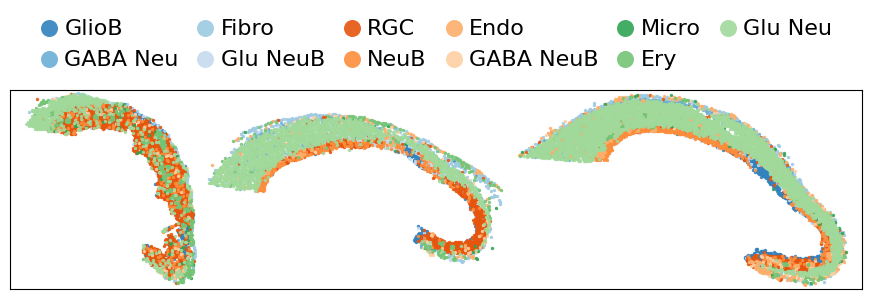

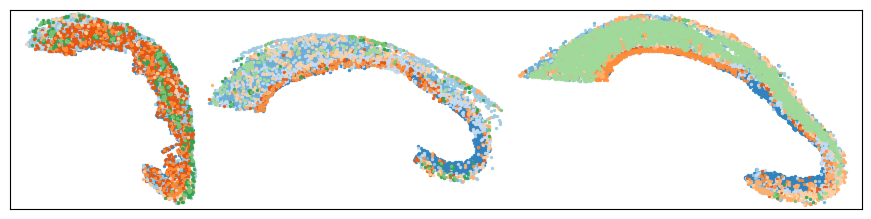

In [17]:
cmap = 'tab20c'
fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_insamp,
    obs_key="annotation",
    coord_keys=("x", "y"),      # uses ad.obs['x'], ad.obs['y'] if present
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    order_key=None,     # optional; requires each slice has exactly one time_point
    # order_map={"E10.5": 10.5, "E11.5": 11.5},  # optional helper
    y_scale=1.0,
    x_gap = 1050,
    s=6,
    legend_loc='upper center',
    legend_bbox=(0.5,0.8),
    legend_ncol = 6,
    legend_font=16,
    truth_key="pred_label",
    truth_cmap=cmap
)
plt.show()

fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_insamp,
    obs_key="pred_label",
    coord_keys=("x", "y"),      # uses ad.obs['x'], ad.obs['y'] if present
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    order_key=None,     # optional; requires each slice has exactly one time_point
    # order_map={"E10.5": 10.5, "E11.5": 11.5},  # optional helper
    y_scale=1.0,
    x_gap = 1050,
    s=6,
    legend=False,
    truth_key="pred_label",
    truth_cmap=cmap
)
plt.show()


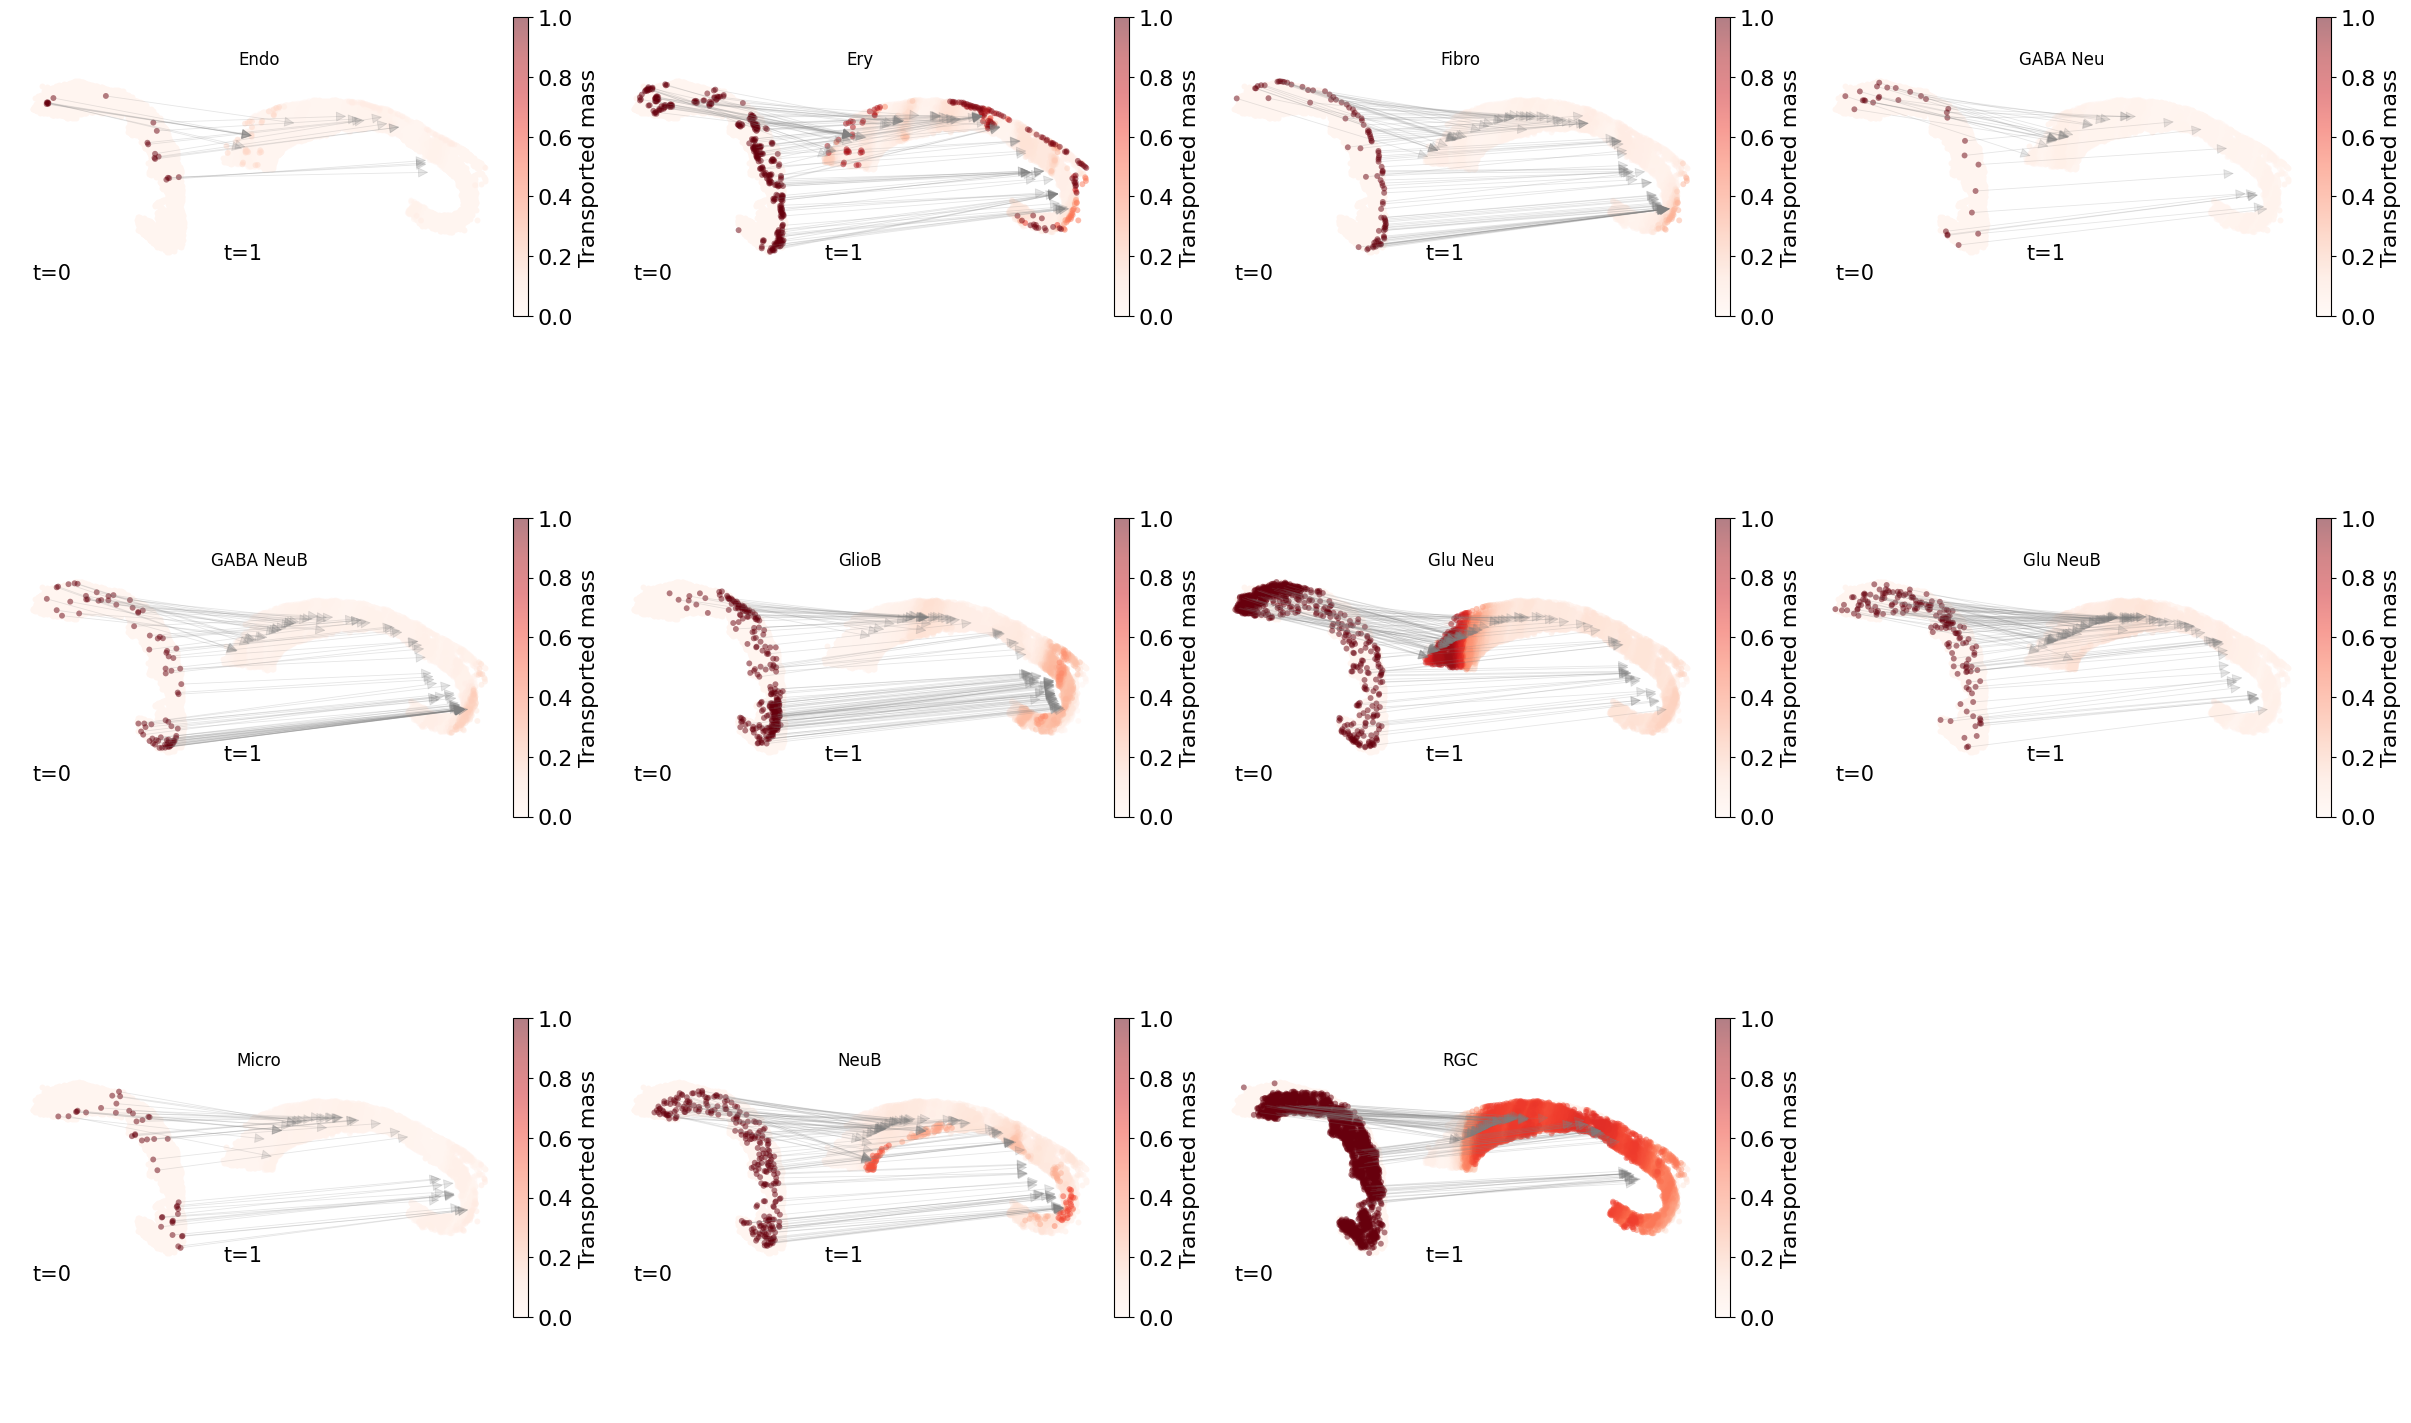

In [18]:
import math

pi_dense = [p.toarray() if sp.issparse(p) else np.asarray(p) for p in pi]


cell_types = list(adata_insamp[0].obs["annotation"].unique())
cell_types = sorted(cell_types)   
n = len(cell_types)

ncols = 4                         
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(6 * ncols, 5 * nrows),   
    constrained_layout=True
)


axes = np.asarray(axes).reshape(-1)


for i, cell_type in enumerate(cell_types):
    ax = axes[i]

    
    fig_i, ax_i, masses = plot_mass_transport_heatmap(
        adata_insamp,
        V,
        pi_dense,
        t_start=0,
        t_end=1,
        source_celltype=cell_type,
        celltype_obs_key="annotation",
        source_mass_source="obs",
        y_gap=4800,
        y_scale=1.0,
        show_edges=True,
        n_sources_show = 100,
        alpha=0.5,
        cmap="Reds",
        edge_alpha=0.2,
        ax=ax,          
        fig=fig,        
       
    )

    ax.set_title(str(cell_type), fontsize=12)

# --- 4) Turn off any unused axes (if grid > n)
for j in range(n, len(axes)):
    axes[j].axis("off")

# Now try an interpolation between the first and last slices

In [19]:
n_time = 3

def norm_rows(V):
    V = np.asarray(V)
    row_sum = V.sum(axis=1, keepdims=True)
    return V / np.where(row_sum == 0, 1.0, row_sum)

X1 = np.vstack([adata_insamp[-1].obs['x'], adata_insamp[-1].obs['y']]).T
X0 = np.vstack([adata_insamp[0].obs['x'],  adata_insamp[0].obs['y']]).T
Y1 = norm_rows(V[-1])
Y0 = norm_rows(V[0])

X_aligned_list = []
X_true_list    = []
Y_bar_list     = []
Y_true_list    = []

X_true        = np.vstack([adata_insamp[0].obs['x'], adata_insamp[0].obs['y']]).T
for i in range(3):
    X_bar, Y_bar, C_bar, log = impute_slice_fgw_barycenter(
        X0, Y0, X1, Y1,
        t=0.25 * (i + 1),
        N_bary=3000,
        alpha=0.5,
        random_state=42,
        n_input=1000
    )
    # X_true        = np.vstack([adata_insamp[i+1].obs['x'], adata_insamp[i+1].obs['y']]).T
    X_bar_aligned = align_by_pca(X_bar, X_true)

    X_aligned_list.append(X_bar_aligned)
    # X_true_list.append(X_true)
    Y_bar_list.append(norm_rows(Y_bar))   # normalized
    # Y_true_list.append(norm_rows(V_true_temporal[i+1]))

# To inspect a specific gene:

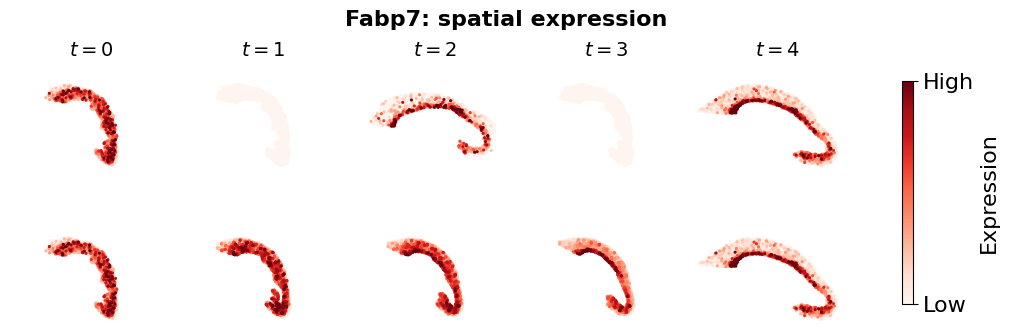

In [20]:
gene = 'Fabp7'

def blank(like):
    """Empty panel with the same coords as another, for padding a short row."""
    X, _ = like
    return X, np.zeros(len(X))


truth = [
    panel(adata_insamp[0], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[1], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[2], gene),
]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="panel", cmap='Reds')

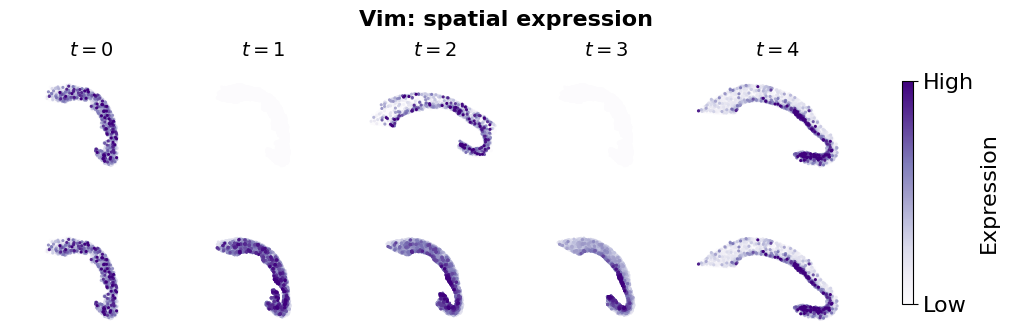

In [21]:
gene = 'Vim'

def blank(like):
    """Empty panel with the same coords as another, for padding a short row."""
    X, _ = like
    return X, np.zeros(len(X))


truth = [
    panel(adata_insamp[0], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[1], gene),
    blank(panel(adata_insamp[0], gene)),
    panel(adata_insamp[2], gene),
]
atlis = [panel(Y, gene, coords=X, basis=pd_B)
         for Y, X in zip(Y_bar_list, X_aligned_list)]

rows = {
    "Truth": truth,
    "ATLIS": [truth[0]] + atlis + [truth[-1]],
}
fig=plot_gene_panels(gene, rows, color_mode="panel", cmap='Purples')

In [38]:
from downstream import analyze_cluster_dynamics
cluster_time_df, cluster_celltype_df, cluster_label_df, cluster_time_counts, cluster_markers = analyze_cluster_dynamics(
    adata_insamp,
    V,
    pd_B,
    cluster_key="pred_label",
    time_key="Time point")

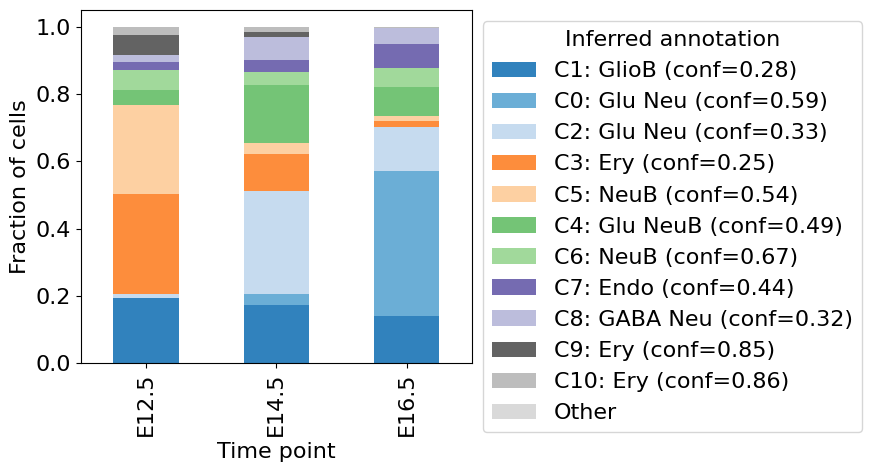

In [47]:
def sort_hpf_index(df):
    idx = df.index.astype(str)
    nums = idx.str.replace("E", "", regex=False).astype(float)
    return df.iloc[np.argsort(nums)]

def extract_cluster_id(colname):
    m = re.match(r"(C\d+)", colname)
    if m is None:
        return None
    return m.group(1)
    
cluster_to_label = {
    row.cluster: f"C{row.cluster}: {row.label} (conf={row.confidence:.2f})"
    for _, row in cluster_label_df.iterrows()
}

plot_df = cluster_time_counts.T.rename(columns=cluster_to_label)
plot_df = sort_hpf_index(plot_df)                               
plot_df = plot_df.div(plot_df.sum(axis=1), axis=0)              # fractions

K = 12
top_types = plot_df.mean(axis=0).sort_values(ascending=False).head(K).index
plot_df["Other"] = plot_df.drop(columns=top_types).sum(axis=1)
plot_df = plot_df[top_types.tolist() + ["Other"]]




plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 16
ax = plot_df.plot(kind="bar", stacked=True, cmap='tab20c')# color=colors)
ax.set_ylabel("Fraction of cells")                              # FIX
ax.set_xlabel("Time point")
ax.legend(title="Inferred annotation", bbox_to_anchor=(1.0, 1), loc="upper left")
plt.tight_layout()
# plt.savefig('../Figures/ZESTA/inferred_clusters.png',bbox_inches='tight')
plt.show()

/tmp/ipykernel_1817456/3929006783.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.title(adata_insamp[t].obs['Time point'][0])


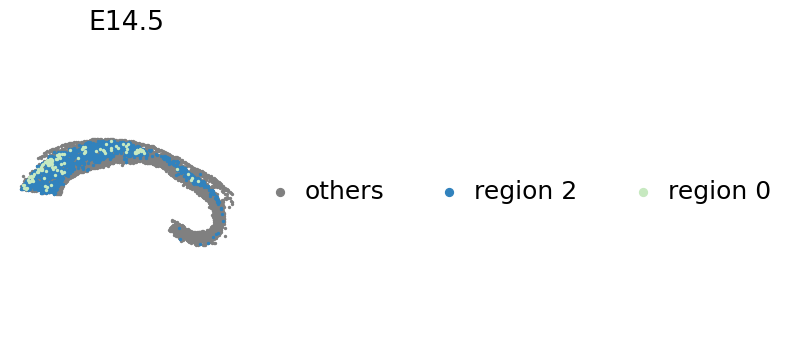

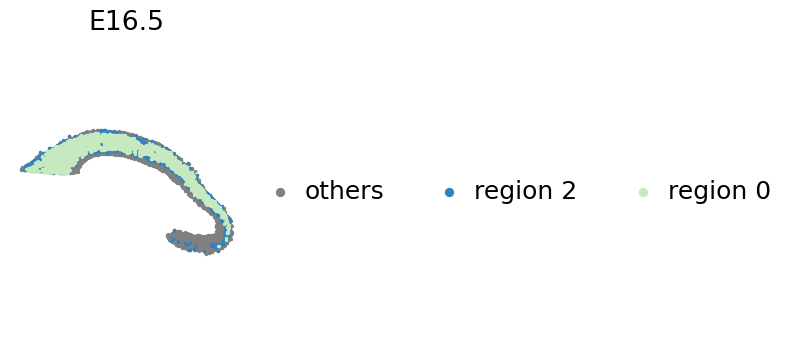

In [42]:
plt.rcParams['figure.figsize'] = (3,4)
cmap = plt.get_cmap("tab20c")
colors = cmap(np.linspace(0, 11/20, 20))

for t in [1,2]:
    plt.scatter(adata_insamp[t].obs['x'], adata_insamp[t].obs['y'], c='gray', s=2, label='others')
    plt.scatter(adata_insamp[t][adata_insamp[t].obs["pred_label"] == 2].obs['x'], adata_insamp[t][adata_insamp[t].obs["pred_label"] == 2].obs['y'], s=2,  color=colors[0],  label='region 2')
    plt.scatter(adata_insamp[t][adata_insamp[t].obs["pred_label"] == 0].obs['x'], adata_insamp[t][adata_insamp[t].obs["pred_label"] == 0].obs['y'], s=2,  color=colors[-1], label='region 0')
    
    plt.axis('equal')
    plt.axis('off')
    plt.legend(
            frameon=False,
            fontsize=18,
            markerscale=4,      # makes legend dots larger
            handlelength=1.2,
            handletextpad=0.4,
            borderpad=0.2,
            labelspacing=0.5,
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            ncol=3
    )
    plt.title(adata_insamp[t].obs['Time point'][0])
    plt.show()

/home/zhaow/miniforge3/lib/python3.13/site-packages/scanpy/plotting/_anndata.py:965: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


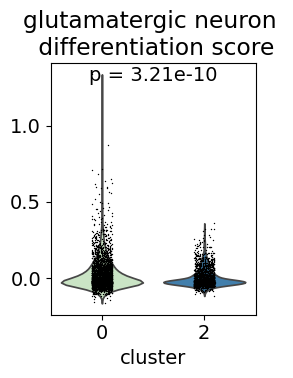

In [44]:

def present(ad, genes):
    gs = [g for g in genes if g in ad.var_names]
    if len(gs) == 0:
        raise ValueError(f"None of these genes are present: {genes}")
    return gs

glu_neu_genes = [
    "Atp2b2",
    "Bbs10",
    "Bhlhe22",
    "Cabp4",
    "Casz1",
    "Cbln1",
    "Cntnap2",
    "Gnat2",
    "Grid2",
    "Ikzf1",
    "Irx5",
    "Irx6",
    "Kndc1",
    "Lbx1",
    "Naglu",
    "Ndp",
    "Nfix",
    "Nrxn1",
    "Ophn1",
    "Pax6",
    "Prdm1",
    "Prox1",
    "Rho",
    "Ulk1",
    "Vsx1",
    "Vsx2",
    "Wnt7a",
    "Zhx2",
]
adata_cat = ad.concat(adata_insamp)

glu_core   = present(adata_cat, glu_neu_genes)

sc.tl.score_genes(adata_cat, glu_core,   score_name="glu_score")

from scipy.stats import mannwhitneyu

x0 = adata_cat.obs.loc[adata_cat.obs["pred_label"] == 0, "glu_score"]
x1 = adata_cat.obs.loc[adata_cat.obs["pred_label"] == 2, "glu_score"]

stat, pval = mannwhitneyu(x0, x1, alternative="two-sided")
sub = adata_cat[adata_cat.obs["pred_label"].isin([0, 2])]

plt.rcParams["font.size"] = 14
fig, axes = plt.subplots(1, 1, figsize=(3, 4))

sc.pl.violin(sub, keys="glu_score", groupby="pred_label",
             stripplot=True, ax=axes, show=False,
             palette=[colors[-1], colors[0]])
axes.set_title("glutamatergic neuron \n differentiation score")
axes.set_ylabel("")

ymax = sub.obs["glu_score"].max()
axes.text(0.5, ymax * 0.95, f"p = {pval:.2e}", ha="center", va="bottom")
axes.set_xlabel("cluster")
plt.tight_layout()
